# Stationarity, Autocorrelation, and Why We Forecast Returns instead of Prices

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to November 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |


**Remote Environments:**

Do your best to set up your local environment as guided during the lab, however, if you have challenges setting it up, then you can use the following remote environments temporarily for the lab:<br/>

[![Colab](https://img.shields.io/badge/Open-Colab-orange?logo=googlecolab)](
https://colab.research.google.com/github/course-files/TimeSeriesForecastingandNeuralNetworks/blob/main/2_stationarity_and_returns.ipynb) (preferred option)

[![Codespaces](https://img.shields.io/badge/Open-Codespaces-blue?logo=github)](
https://github.com/codespaces/new/course-files/TimeSeriesForecastingandNeuralNetworks) (alternative)

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Recognize a stationary and a non-stationary series by eye, and confirm your judgement using the ADF and KPSS tests.
2. Apply differencing and the logarithm to make a series stationary, and explain what each one does.
3. Read an ACF and a PACF plot.
4. Explain why regressing one price on another can produce a "significant" relationship that is not real (spurious regression).
5. Explain why the rest of the lab forecasts **returns** and not prices.
6. Explain what **volatility clustering** and why volatility is far easier to forecast than direction.

**Prerequisites:** Notebook 1, and the lecture slides on components of a time series and on stationarity.

## Recall: What Is Stationarity?

A time series is (weakly) stationary when three things do not depend on **when** you look:

1. The **mean** stays around the same value.
2. The **variance** stays around the same value.
3. The **autocorrelation** (how today relates to the day before, or ten days before) depends only on the gap between the two days, not on the calendar date.

Why do we care? Most statistical forecasting methods, and the tests built on them, learn a relationship from the past and assume that it still holds in the future. If the mean and the spread keep drifting, a relationship learned from 2017 describes a different series from the one you are forecasting in 2027.

Our plan in this notebook is to take the closing price, show that it is not stationary, and then discover that the daily **return** is stationary.

## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# This block does nothing in your local environment (your laptop).
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: C:\Users\Eggy\AppData\Local\Python\pythoncore-3.12-64\python.exe
Python version    : 3.12.4


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tests and models from statsmodels and arch
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose
import statsmodels.api as sm
from arch import arch_model

from tslab import config
from tslab.data import load_market_data
from tslab.plots import plot_acf_pacf

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

## Step 2: Load the Data and Create the Series We Will Study

In [3]:
data = load_market_data()

price = data["Close"]                       # the closing price
log_price = np.log(price)                   # the logarithm of the price
price_change = price.diff().dropna()        # first difference of the price (in dollars)
log_return = log_price.diff().dropna()      # first difference of the log price = the log return

Loaded 2981 trading days of GOOGL, 2015-01-02 to 2026-11-09, with 7 predictor series.


## Step 3: Look First

Before any test, look at the plot. The lecture lists the visual signs of a series that is **not** stationary: a trend, a spread that changes over time, and a repeating seasonal pattern.

We plot each series together with its **rolling mean** and **rolling standard deviation**, using a window of 63 trading days (about one quarter). If the series is stationary, both rolling lines should be roughly flat.

**Note:** A rolling statistic is calculated over a window that moves forward one day at a time, instead of over the whole series. It is similar to a sliding window in programming.

With a window of 63 days, the rolling mean for today is the average of the last 63 trading days. Tomorrow, the oldest day drops out, the newest day comes in, and the average is recalculated. The rolling standard deviation works the same way and measures how much the values vary within that window.

Plotting these values over time shows how the level and the spread of the series change. If the series is stationary, both lines stay roughly flat. A rolling mean that climbs or falls indicates a trend, and a rolling standard deviation that grows or shrinks indicates a changing spread.

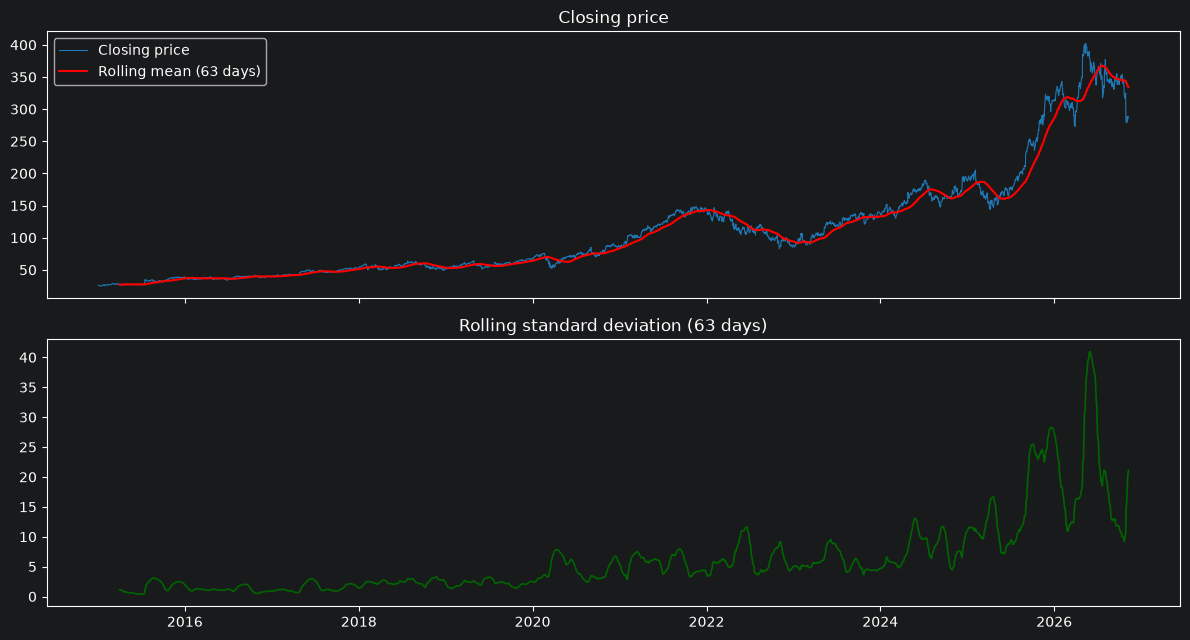

In [4]:
def plot_with_rolling(series, title, window=63):
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
    top.plot(series, color="tab:blue", linewidth=0.8, label=title)
    top.plot(series.rolling(window).mean(), color="red", linewidth=1.5, label=f"Rolling mean ({window} days)")
    top.legend(loc="upper left")
    top.set_title(title)
    bottom.plot(series.rolling(window).std(), color="darkgreen", linewidth=1.2)
    bottom.set_title(f"Rolling standard deviation ({window} days)")
    plt.tight_layout()
    plt.show()

plot_with_rolling(price, "Closing price")

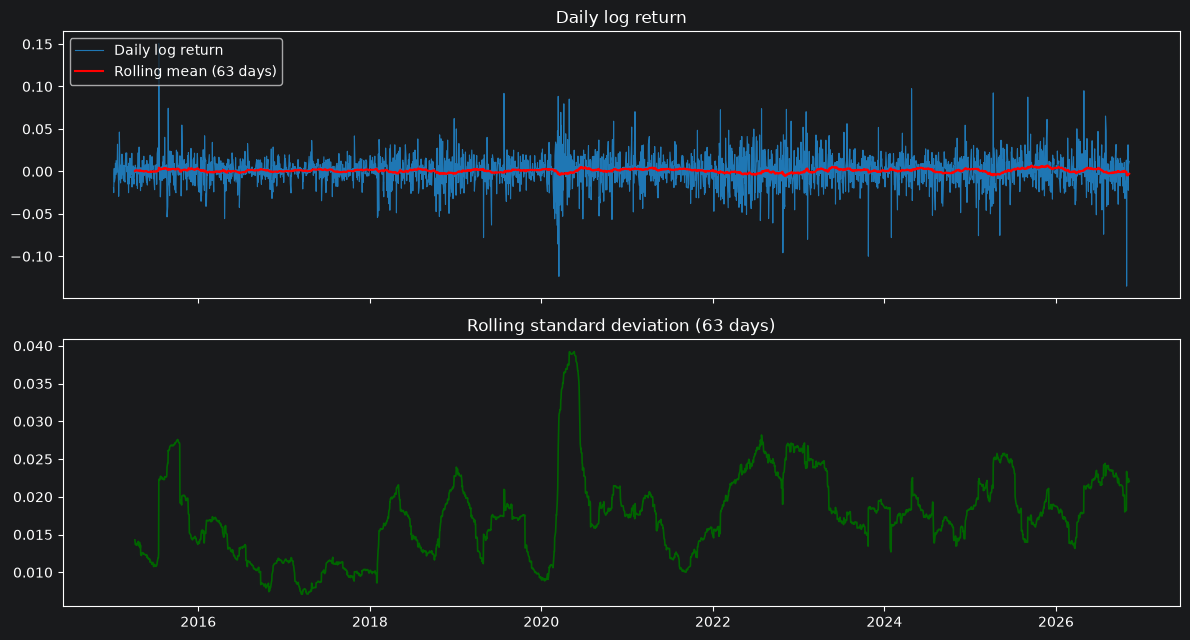

In [5]:
plot_with_rolling(log_return, "Daily log return")

Compare the two figures.

- The **price** goes up over the years. Its rolling mean moves up and down with it, and the rolling spread is larger when the price level is higher. Neither is flat. This series is not stationary.
- The **return** fluctuates around zero. The rolling mean stays close to zero. The rolling standard deviation is **not perfectly flat** (it rises in turbulent periods), and we will come back to that in a later Step in this notebook. But the series has a stable centre and does not wander away.

## Step 4: Test Statistically

Visual interpretation can be misleading and subjective. We, therefore, use statistical tests to confirm whether a series is stationary or not.

The two statistical tests below ask opposite questions on purpose.

| Test | Null hypothesis (H0) | Small p-value (below 0.05) means |
|:-----|:---------------------|:---------------------------------|
| **ADF** (Augmented Dickey-Fuller) | The series has a unit root (it is **non-stationary**) | Reject H0: the series looks **stationary** |
| **KPSS** (Kwiatkowski-Phillips-Schmidt-Shin) | The series is **stationary** | Reject H0: the series looks **non-stationary** |

---

**Note:**

A unit root means that each value equals the previous value plus a random shock, and that shock is never forgotten:

`yesterday’s value + random shock = today’s value`

This is a random walk. Nothing pulls the series back toward a fixed average, so it can wander off and stay away. Its spread also grows as time passes, which is why it fails the stationarity requirements.

The contrast case is a series where only part of yesterday’s value carries over, for example half of it plus a shock. In such a case, the shocks fade, and the series keeps returning to its average. That is a stationary series. The name “unit root” refers to the carry-over factor being exactly 1, meaning that the whole of yesterday’s value carries over.

**Analogy:** a dog on a leash that always returns to its human (stationary) and a person walking with no destination (unit root).

This also explains why we work with returns. Subtracting yesterday’s value from today’s leaves only the random shock, which removes the unit root. Stock prices typically behave like a random walk, and their returns usually do not.

---

Because the hypotheses are reversed, using both gives you a stronger conclusion:

| ADF says | KPSS says | Conclusion |
|:---------|:----------|:-----------|
| Stationary | Stationary | Stationary |
| Non-stationary | Non-stationary | Non-stationary |
| Stationary | Non-stationary | Difference stationary: differencing is needed (or, the series is stationary around a trend) |
| Non-stationary | Stationary | Trend stationary: remove the trend, or the test has little power in this sample |

(`autolag="AIC"` in the ADF test asks it to choose the number of lagged terms that best explains the data without overfitting.)

In [6]:
def stationarity_report(series, name):
    """Run the ADF and KPSS tests on one series and return a one-row summary."""
    adf_p = adfuller(series.dropna(), autolag="AIC")[1]
    kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
    adf_says_stationary = adf_p < 0.05
    kpss_says_stationary = kpss_p >= 0.05
    if adf_says_stationary and kpss_says_stationary:
        verdict = "Stationary"
    elif not adf_says_stationary and not kpss_says_stationary:
        verdict = "Non-stationary"
    else:
        verdict = "Conflicting: look closer"
    return {"Series": name, "ADF p-value": adf_p, "KPSS p-value": kpss_p, "Verdict": verdict}

table = pd.DataFrame([
    stationarity_report(price, "Closing price"),
    stationarity_report(log_price, "Log of the closing price"),
    stationarity_report(price_change, "First difference of the price"),
    stationarity_report(log_return, "Log return (first difference of the log price)"),
]).set_index("Series")
table.round(4)

,ADF p-value,KPSS p-value,Verdict
Series,,,
Closing price,0.9554,0.01,Non-stationary
Log of the closing price,0.8298,0.01,Non-stationary
First difference of the price,0.0000,0.10,Stationary
Log return (first difference of the log price),0.0000,0.10,Stationary


(KPSS p-values are reported between 0.01 and 0.10. A printed 0.01 means "0.01 or smaller", and 0.10 means "0.10 or larger".)

Read the table. The log transformation alone does **not** make a trending series stationary. It stabilizes the variance (the spread no longer grows with the price level), but the series still wanders. **Differencing** removes the "wandering". The log return is the difference of the log price, so it does both jobs at once.

This is why ARIMA has an "I" in its name. The "I" stands for **Integrated**: the model differences the series internally (the parameter `d`) so that the remaining series is stationary.

## Step 5: The Transformations from the Lecture

The lecture introduced four ways to make a series stationary. We apply each one to the closing price and test the result, so that you can see which ones work for **stock prices**.

In [7]:
# 1. Differencing: Y(t) - Y(t-1)
differenced = price.diff().dropna()

# 2. Detrending: fit a straight line through time, and subtract it

# Number the observations 0, 1, 2, ..., n-1 to use as the "time" variable (x-axis).
# reshape(-1, 1) makes it a column vector (n rows x 1 column).
time_index = np.arange(len(price)).reshape(-1, 1)

# np.polyfit(x, y, deg=1) fits a straight line (price ≈ slope * t + intercept) by least squares
# and returns [slope, intercept]. np.poly1d(...) turns those into a callable line function,
# and calling it on time_index gives the fitted trend value at each time step.
# .ravel() flattens the column vector back to 1-D, which polyfit and poly1d expect.
trend_line = np.poly1d(np.polyfit(time_index.ravel(), price.values, deg=1))(time_index.ravel())

# Subtract the trend from the actual prices to leave the deviations around the line.
# Wrapping the result in a pd.Series with the original dates keeps it aligned for plotting.
detrended = pd.Series(price.values - trend_line, index=price.index)


# 3. Log transformation: stabilizes a variance that grows with the level
logged = np.log(price)

# 4. Seasonal differencing: Y(t) - Y(t-63), one quarter earlier
seasonal_differenced = price.diff(63).dropna()

# Combination used most often for prices: log, then difference
log_then_difference = np.log(price).diff().dropna()

pd.DataFrame([
    stationarity_report(price, "Original price"),
    stationarity_report(differenced, "Differenced"),
    stationarity_report(detrended, "Detrended (straight line removed)"),
    stationarity_report(logged, "Log transformed"),
    stationarity_report(seasonal_differenced, "Seasonal differenced (63 days)"),
    stationarity_report(log_then_difference, "Log transformed, then differenced"),
]).set_index("Series").round(4)

,ADF p-value,KPSS p-value,Verdict
Series,,,
Original price,0.9554,0.01,Non-stationary
Differenced,0.0000,0.10,Stationary
Detrended (straight line removed),0.3742,0.01,Non-stationary
Log transformed,0.8298,0.01,Non-stationary
Seasonal differenced (63 days),0.0000,0.01,Conflicting: look closer
"Log transformed, then differenced",0.0000,0.10,Stationary


What to take from this table:

- **Detrending** removes a **deterministic** trend (a straight line). A stock's trend is **stochastic**: it does not follow a line, it drifts unpredictably. Subtracting a line therefore usually leaves a series that still wanders.
- **Seasonal differencing** is designed to remove a repeating pattern. A 63-day difference can pass the ADF test, but only because it is a long **change** in price, which is differencing again. There was no stable seasonal pattern to remove (we check this in subsequent steps).
- **Differencing** and **log then differencing** are the transformations that matter for prices.
- Differencing the price gives a series whose spread still grows with the price level, which is why the log version is preferred.

**A warning on over-differencing.** If a series is already stationary, differencing it again makes it noisier and introduces artificial negative autocorrelation. Difference only as much as you need. For stock prices, one difference of the log is almost always enough.

## Step 6: Autocorrelation: Does Yesterday Help Predict Today?

The **autocorrelation function (ACF)** measures the correlation between a series and a copy of itself shifted by *k* days (the lag). The **partial autocorrelation function (PACF)** measures the same thing after removing the effect of the lags in between. These two plots are the tools we use to choose the `p` and `q` parameters in an ARIMA model.

The blue band in each plot is an approximate 95 percent confidence band for "no autocorrelation". Bars that stay inside the band are indistinguishable from zero.

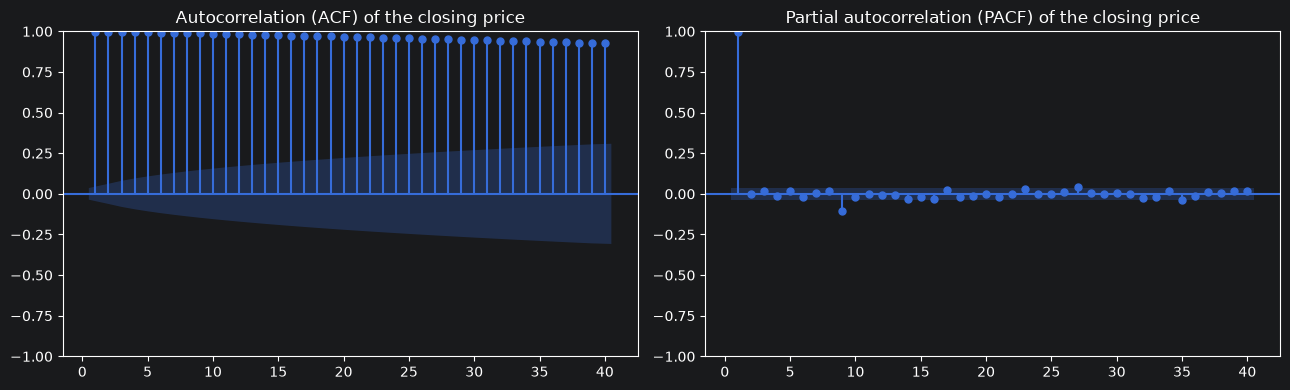

In [8]:
plot_acf_pacf(price, lags=40, title="of the closing price")

The ACF of the price decays very slowly and stays high for dozens of lags. That is the signature of a non-stationary series: today's price is strongly related to the price of almost every recent day, simply because the price drifts rather than jumping around.

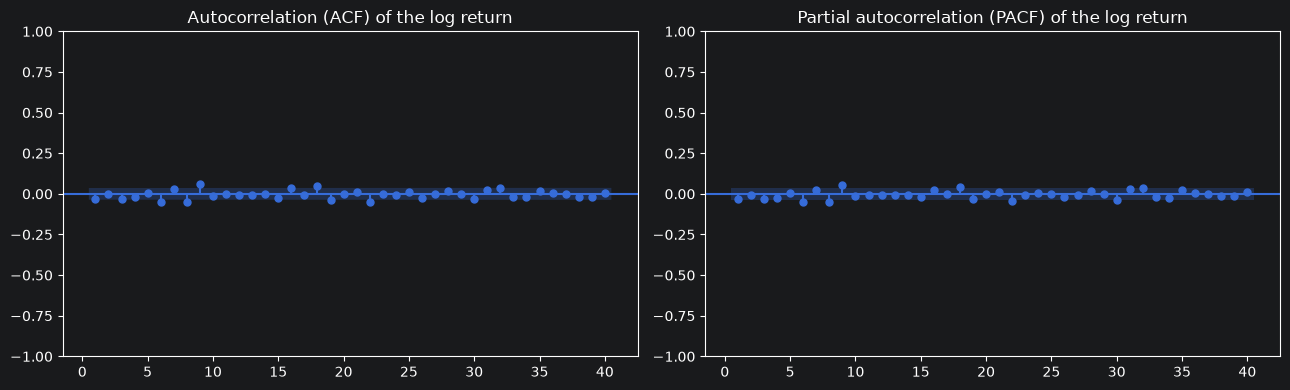

In [9]:
plot_acf_pacf(log_return, lags=40, title="of the log return")

For the daily return, count how many bars poke outside the band. With 40 lags, and a 95 percent band, you would expect about two bars to exceed it by chance alone even if the series had no structure at all. If you see roughly that many, and all the bar heights are small, the return has almost no linear memory. **Yesterday's return tells you very little about today's return.**

We can test that formally using the **Ljung-Box test**. Its null hypothesis is that there is no autocorrelation up to the stated lag. A small p-value means there is some.

In [10]:
lb = acorr_ljungbox(log_return, lags=[5, 10, 21], return_df=True)
lb.rename(columns={"lb_stat": "Statistic", "lb_pvalue": "p-value"})

,Statistic,p-value
5,7.085470,0.214361
10,36.582256,0.000067
21,54.452709,0.000085


Read this table carefully. The p-values at lags 10 and 21 are small, so the test does find some linear memory in the daily returns. That does **not** mean the returns are easy to forecast. With almost three thousand observations the test is powerful enough to detect very small correlations, and a correlation that is statistically detectable can still be too small to earn money after trading costs. Keep these numbers in mind, and compare their size with the table for the squared returns below.

### The same plot for the size of returns

Now look at the ACF of the **absolute** return and the **squared** return. These measure the size of a move and ignore its direction.

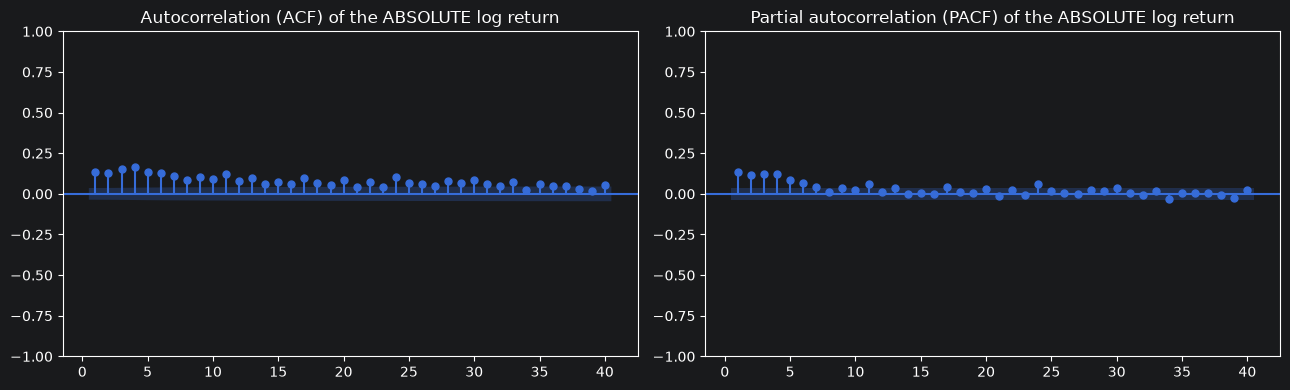

In [11]:
plot_acf_pacf(log_return.abs(), lags=40, title="of the ABSOLUTE log return")

In [12]:
lb_sq = acorr_ljungbox(log_return ** 2, lags=[5, 10, 21], return_df=True)
lb_sq.rename(columns={"lb_stat": "Statistic", "lb_pvalue": "p-value"})

,Statistic,p-value
5,118.609105,6.184345e-24
10,163.609705,5.821058e-30
21,203.741366,6.641992e-32


This is a very different picture. The autocorrelation of the **size** of returns is clearly positive for many lags. A big move today is followed by more big moves, in either direction. This is **volatility clustering**.

Put the two ideas together:

> The **direction** of tomorrow's return is almost unrelated to the past.
> The **size** of tomorrow's move is strongly related to the past.

This one finding explains much of what you will see in the remaining notebooks.

### Volatility Clustering

**Volatility clustering is the tendency of large price movements to be followed by more large movements, and calm periods to be followed by more calm periods.** In other words, turbulence and quiet both come in stretches rather than being scattered randomly.

A simple way to picture it: if a stock swings sharply today, up or down, it is likely to swing sharply tomorrow as well. If it has barely moved for a week, it will probably stay fairly steady for a while. The direction of the next move remains hard to predict, but the size of the next move is partly predictable from recent behavior.

On a plot of daily log returns, this shows up as bursts of tall spikes (for example, around a financial crisis or a major announcement) separated by long stretches of small, tightly packed movements.

This matters for forecasting because it means returns can look uncorrelated while their magnitudes are not. That is why a series can pass the stationarity tests yet still have changing variance over time, which is the motivation for models such as **ARCH** and **GARCH**.

## Step 7: Spurious Regression (Why We Do Not Regress Price on Price)

Suppose a colleague regresses the price of the stock on the price of gold and reports a high R squared and a tiny p-value. **Is that evidence that gold predicts the stock?**

First, an experiment with **random numbers**. We generate 500 pairs of **independent** random walks. By construction, there is no relationship at all between the two series in a pair. We regress one on the other and record how often the slope looks "statistically significant".

In [13]:
rng = np.random.default_rng(config.SEED)
n_pairs, n_steps = 500, 1000
significant_levels, significant_changes = 0, 0
r2_levels = []

for _ in range(n_pairs):
    x = np.cumsum(rng.standard_normal(n_steps))   # a random walk
    y = np.cumsum(rng.standard_normal(n_steps))   # another, independent random walk

    fit_levels = sm.OLS(y, sm.add_constant(x)).fit()
    significant_levels += fit_levels.pvalues[1] < 0.05
    r2_levels.append(fit_levels.rsquared)

    fit_changes = sm.OLS(np.diff(y), sm.add_constant(np.diff(x))).fit()
    significant_changes += fit_changes.pvalues[1] < 0.05

print(f"Regressing LEVEL on LEVEL     : slope 'significant' in {significant_levels / n_pairs:.0%} of the pairs, average R squared {np.mean(r2_levels):.2f}")
print(f"Regressing CHANGE on CHANGE   : slope 'significant' in {significant_changes / n_pairs:.0%} of the pairs")

Regressing LEVEL on LEVEL     : slope 'significant' in 92% of the pairs, average R squared 0.24
Regressing CHANGE on CHANGE   : slope 'significant' in 3% of the pairs


The result is striking. We generated pairs of series that have nothing to do with each other. When we regressed one on the other using the levels (the raw values), the regression reported a "significant" relationship in most cases. When we regressed their changes (the day-to-day differences) instead, it reported a relationship in only about 5 percent of cases, which is the false alarm rate we expect. This is called the **spurious regression problem**. Two series that wander over time will look related simply because both are wandering, not because one explains the other.

Now we repeat the comparison with real data: the stock against gold.

**Analogy:** two people walking at random, each in their own direction, may both end up far from where they started. Comparing where they stand makes them look connected. Comparing each step they take shows that they are not.

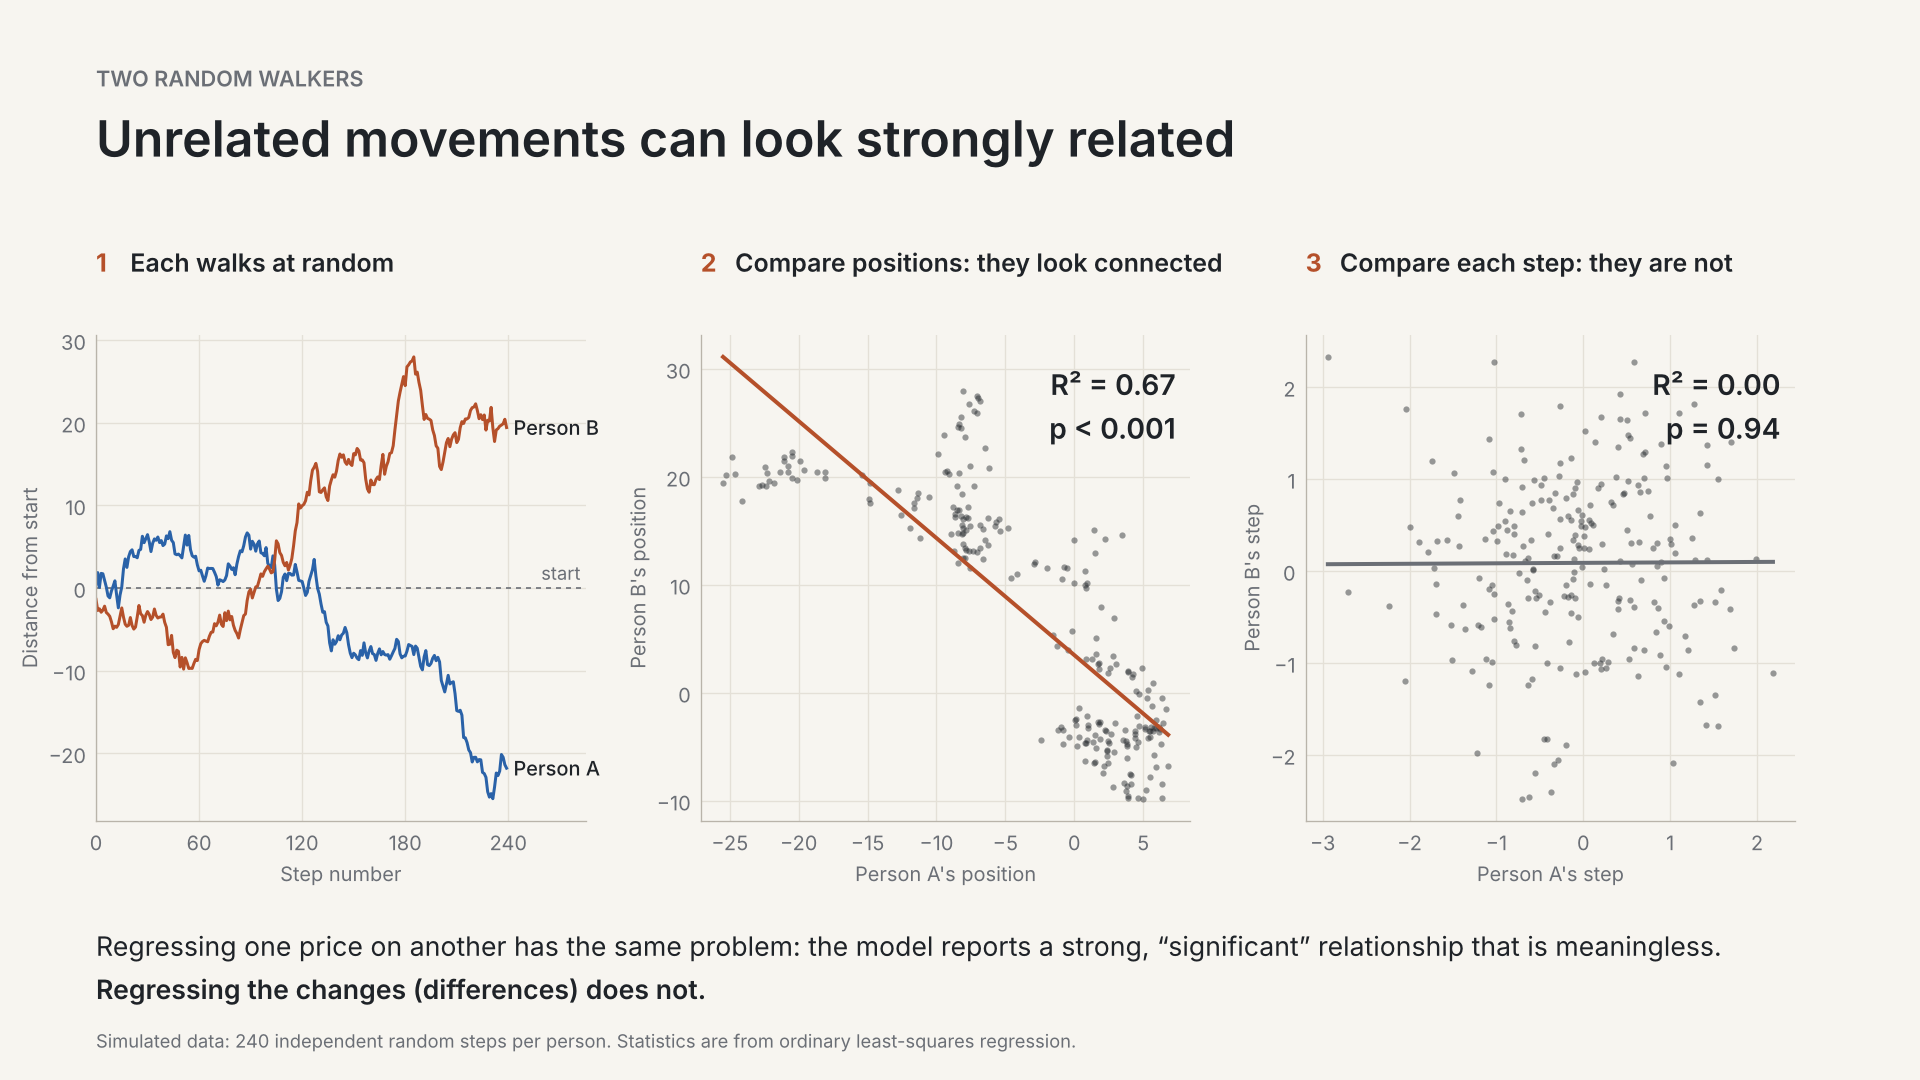

In [14]:
from IPython.display import Image, display
display(Image(filename="assets/images/spurious_regression.png", width=700))

In [15]:
# Levels: log price on log price
levels = sm.OLS(np.log(data["Close"]), sm.add_constant(np.log(data["GOLD"]))).fit()

# Changes: daily log return on daily log return
stock_ret = np.log(data["Close"]).diff().dropna()
gold_ret = np.log(data["GOLD"]).diff().dropna()
changes = sm.OLS(stock_ret, sm.add_constant(gold_ret)).fit()

print(f"Levels : R squared = {levels.rsquared:.3f}   p-value of the slope = {levels.pvalues.iloc[1]:.2e}")
print(f"Changes: R squared = {changes.rsquared:.4f}   p-value of the slope = {changes.pvalues.iloc[1]:.2e}")

Levels : R squared = 0.878   p-value of the slope = 0.00e+00
Changes: R squared = 0.0025   p-value of the slope = 6.22e-03


Compare the two R squared values. The regression on levels is likely to look impressive, and the regression on daily changes is likely to look weak. Which one tells you something about whether **today's gold move helps forecast the stock**? Only the second. The first is mostly "two trends keeping each other company".

**The lesson for the lab:** every predictor we use in the next notebooks enters the model as a **return or a change**, never as a price level. *The exceptions are the Volatility Index (VIX) and the interest rate. They hover around a level instead of drifting away, so a level carries meaning, and Notebook 4 gives you the chance to test whether it does.*

## Step 8: Seasonality, Revisited

The lecture covered seasonal models (e.g., Holt-Winters and SARIMA). Do daily stock prices have a seasonal pattern worth modelling? We decompose the log price into trend, seasonal and residual components, using a seasonal period of 21 trading days (about one month), and compare the **size** of the three parts.

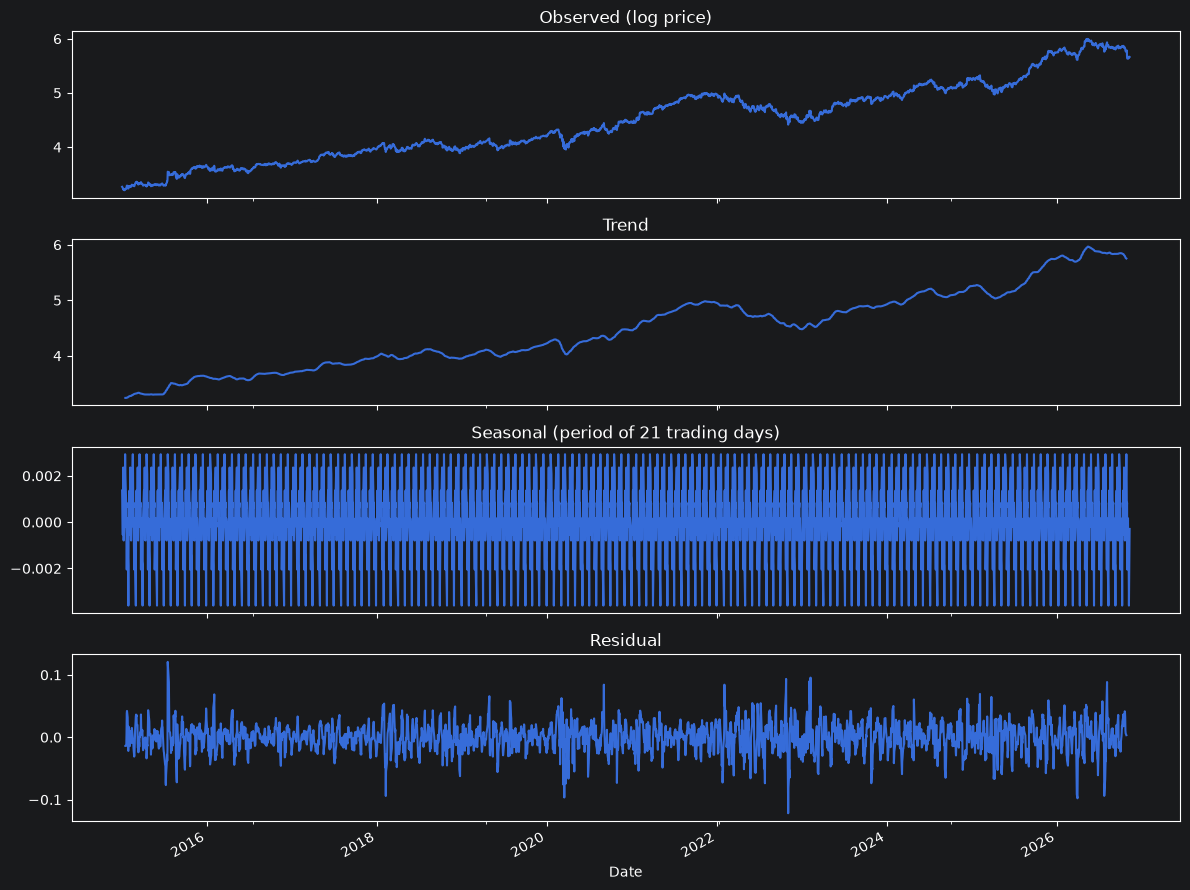

Compare the size of each component: the larger the range,
the more that component contributes to variation in the series
Range of the trend component   : 2.725
Range of the seasonal component: 0.007
Range of the residual          : 0.243


In [16]:
decomposition = seasonal_decompose(np.log(price), model="additive", period=21)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
decomposition.observed.plot(ax=axes[0], title="Observed (log price)")
decomposition.trend.plot(ax=axes[1], title="Trend")
decomposition.seasonal.plot(ax=axes[2], title="Seasonal (period of 21 trading days)")
decomposition.resid.plot(ax=axes[3], title="Residual")
plt.tight_layout()
plt.show()

# lambda creates a small one-line anonymous function: "lambda s:" takes an input s
# and returns the expression after the colon (same as def spread(s): return ...)

# Helper: range (max - min) of a series, ignoring NaNs
# (trend/resid have NaNs at the edges from the moving average)
spread = lambda s: s.dropna().max() - s.dropna().min()

print("Compare the size of each component: the larger the range,"
      "\nthe more that component contributes to variation in the series")
print(f"Range of the trend component   : {spread(decomposition.trend):.3f}")     # long-term movement
print(f"Range of the seasonal component: {spread(decomposition.seasonal):.3f}")  # repeating periodic pattern
print(f"Range of the residual          : {spread(decomposition.resid):.3f}")     # leftover noise not explained by trend/seasonality

Compare the three ranges. The seasonal component is tiny compared with the trend and the residual. The decomposition is forced to find a repeating 21-day shape, and what it finds is almost flat.

A calendar pattern, if it exists, would also show up as a different **average return** on certain weekdays or in certain months. We check that directly, and test whether any difference is bigger than random noise.

In [17]:
by_weekday = log_return.groupby(log_return.index.dayofweek).agg(["mean", "std", "count"])
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri"]
by_weekday["t-statistic"] = by_weekday["mean"] / (by_weekday["std"] / np.sqrt(by_weekday["count"]))
by_weekday.round(5)

,mean,std,count,t-statistic
Mon,0.00095,0.01814,558,1.24300
Tue,0.00075,0.01589,614,1.16253
Wed,0.00170,0.02031,611,2.06798
Thu,0.00003,0.01835,601,0.04527
Fri,0.00058,0.01908,596,0.74699


A t-statistic larger than about 2 in absolute size is usually taken as a real difference, but it still happens by chance about 1 time in 20. Here we compare five weekdays, so there are five chances for luck, and the chance that at least one weekday exceeds 2 is roughly one in four. Monday and Wednesday both exceed 2 in our table, so we treat them as hints, not as findings. This is the **multiple comparisons problem**: when you look at many slices of the data, some will look special by chance. A pattern is evidence only if it also holds on data that you did not use to find it.

For daily stock prices, then, we do not expect Holt-Winters or SARIMA to find a stable seasonal pattern. We still include the calendar features in the forecasting models in the next notebooks, and let the data show whether they help.

## Step 9: Size Is Forecastable, Direction Mostly Is Not

There are two different questions about tomorrow.
- Will the price go up or down (direction)?
- And will it move a lot or a little (size)?

In a previous step, we saw that the size of returns comes in clusters: calm days follow calm days, and wild days follow wild days. This makes the size of tomorrow’s move partly predictable.

### Generalized Autoregressive Conditional Heteroscedasticity (GARCH)

The standard model for this is GARCH(1,1). It estimates how bumpy tomorrow is likely to be from three things: the usual level of bumpiness, how bumpy yesterday was, and how big yesterday’s surprise was. We fit it to the daily return in percent, because the optimizer works better with numbers that are not tiny.

In [18]:
returns_pct = log_return * 100

# Fit a GARCH(1,1) model to the returns:
#   returns_pct    : returns in percent (scaling by 100 helps the optimizer converge)
#   mean="Constant": the average return is a single constant (mu)
#   vol="GARCH"    : today's variance depends on past shocks and past variance
#   p=1            : 1 lag of past squared shocks (ARCH term: reaction to recent surprises)
#   q=1            : 1 lag of past variance (GARCH term: how long volatility persists)
#   dist="t"       : Student's t errors, for fat tails (extreme returns happen more often than a normal distribution allows)
garch = arch_model(returns_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="t")

garch = arch_model(returns_pct, mean="Constant", vol="GARCH", p=1, q=1, dist="t")
garch_fit = garch.fit(disp="off")
print(garch_fit.summary().tables[1])
print(garch_fit.summary().tables[2])

                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1296  2.415e-02      5.368  7.968e-08 [8.229e-02,  0.177]
                               Volatility Model                              
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
omega          0.0333  1.953e-02      1.705  8.814e-02 [-4.974e-03,7.159e-02]
alpha[1]       0.0589  1.468e-02      4.014  5.973e-05  [3.015e-02,8.769e-02]
beta[1]        0.9372  1.680e-02     55.785      0.000      [  0.904,  0.970]


In the summary, `alpha[1]` shows how strongly a surprise raises the next day’s bumpiness, and `beta[1]` shows how long the bumpiness lasts (close to 1 means it fades slowly). `mu` shows how often extreme days occur; a smaller value means more extreme days. We use the t distribution because Notebook 1 showed that real returns have extreme days more often than a bell curve suggests.

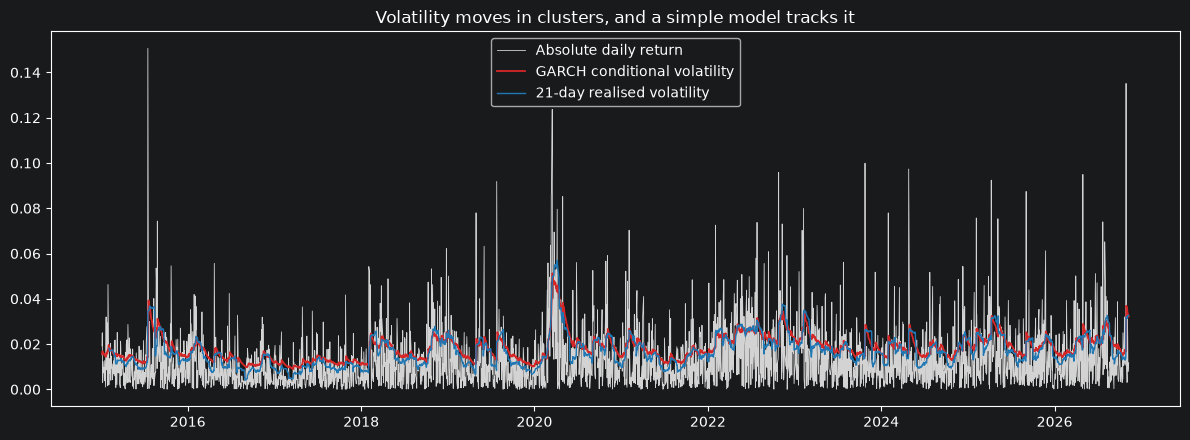

In [19]:
conditional_vol = garch_fit.conditional_volatility / 100        # back to return units
realised_vol = log_return.rolling(21).std()

plt.figure(figsize=(12, 4.5))
plt.plot(log_return.abs(), color="lightgrey", linewidth=0.6, label="Absolute daily return")
plt.plot(conditional_vol, color="tab:red", linewidth=1.3, label="GARCH conditional volatility")
plt.plot(realised_vol, color="tab:blue", linewidth=1, label="21-day realised volatility")
plt.legend()
plt.title("Volatility moves in clusters, and a simple model tracks it")
plt.tight_layout()
plt.show()

The red and blue lines should rise and fall with the grey spikes, which shows that the model tracks the volatility clusters.

In [20]:
# Which is easier to predict from today's information: the NEXT day's direction, or the NEXT day's size?
next_return = log_return.shift(-1)
frame = pd.DataFrame({
    "today_return": log_return,
    "today_garch_vol": conditional_vol,
    "next_return": next_return,
    "next_abs_return": next_return.abs(),
}).dropna()

print("Correlation, today's return vs tomorrow's return        :", round(frame["today_return"].corr(frame["next_return"]), 3))
print("Correlation, today's GARCH volatility vs tomorrow's SIZE:", round(frame["today_garch_vol"].corr(frame["next_abs_return"]), 3))

Correlation, today's return vs tomorrow's return        : -0.032
Correlation, today's GARCH volatility vs tomorrow's SIZE: 0.239


Compare the two numbers. Today’s return says almost nothing about tomorrow’s direction, so the first correlation is close to zero. Today’s volatility says something about tomorrow’s size, so the second correlation is clearly positive.

This is the most important realistic expectation of the module. **Forecasting the size** of moves works well enough that risk managers use it every day. **Forecasting the direction** is much harder, which is why Notebook 4 compares every model with a naïve forecast and tests whether any improvement is real.

## Step 10: Exercises

1. In Step 4, the ADF test on the closing price gives a large p-value and the test on the log return gives a tiny one. Explain in plain language what each result means for forecasting.
2. In Step 4 the log transformation alone did not make the price stationary. What did it achieve instead?
3. Repeat the spurious regression experiment in Step 7, but change `n_steps` to 100, then to 5000. What happens to the share of "significant" relationships? What does that tell you about using more data?
4. Choose any **other** predictor in the table in Notebook 1 and repeat the levels versus changes comparison in Step 7. Does the levels regression look equally impressive?
5. The lecture asked: "Which of the following series is stationary?" (the slide with the nine plots). Without looking at the answer, decide where the **log return of a stock** would sit in that slide, and justify it with the rolling statistics from Step 3.
6. Change the GARCH specification in Step 9 to `dist="normal"`. How do the parameters change, and which fit is better by the log-likelihood in the summary?

## Summary

- A price is **not** stationary. A return **is** (approximately).
- Use ADF and KPSS **together** because their hypotheses are opposite.
- Log stabilises variance. Differencing removes wandering. Detrending and seasonal differencing do not help much for stock prices.
- Regressing level on level can produce a convincing but meaningless result. Use returns and changes.
- The direction of returns has almost no linear memory, while the size of returns clusters. Volatility can be forecast; direction is hard.

**Therefore, from this point on, our target is the next-day log return, and we convert the forecast back to a closing price.**